cargar el nuevo dataset de tunnign

In [2]:
from pathlib import Path
from scipy.io import whosmat

raiz = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "configs").is_dir() and (p / "src").is_dir()
)

archivos = sorted(
    (raiz / "data" / "speech_2023").rglob("*phonem*.mat")
)

if not archivos:
    raise FileNotFoundError("No se encontraron archivos de fonemas.")

for ruta in archivos:
    print(ruta.relative_to(raiz))

archivo = archivos[0]
print("\nVariables de:", archivo.name)

for nombre, forma, tipo in whosmat(archivo):
    print(nombre, forma, tipo)

data/speech_2023/tuningTasks/t12.2022.04.21_phonemes.mat
data/speech_2023/tuningTasks/t12.2022.04.26_phonemes.mat

Variables de: t12.2022.04.21_phonemes.mat
tx1 (127457, 256) uint8
tx2 (127457, 256) uint8
tx3 (127457, 256) uint8
tx4 (127457, 256) uint8
spikePow (127457, 256) single
xpcClock (127457, 1) uint32
nsp1Clock (127457, 1) uint32
nsp2Clock (127457, 1) uint32
redisClock (127457, 1) int64
trialState (127457, 1) double
blockNum (127457, 1) double
trialDelayTimes (640, 1) double
goTrialEpochs (640, 2) double
delayTrialEpochs (640, 2) double
trialCues (640, 1) double
cueList (1, 40) cell
blockList (8, 1) double


contar datuss de cueList y trialCues

In [3]:
import numpy as np
from scipy.io import loadmat
from collections import Counter

datos = loadmat(
    archivo,
    variable_names=["cueList", "trialCues"],
    simplify_cells=True,
)

fonemas = np.asarray(datos["cueList"]).reshape(-1)
ids = np.asarray(datos["trialCues"]).reshape(-1).astype(int)

etiquetas = fonemas[ids - 1]
conteos = Counter(etiquetas)

print("Número de ensayos:", len(etiquetas))
print("Número de condiciones:", len(fonemas))
print()

for fonema in fonemas:
    print(f"{fonema:8s} → {conteos[fonema]} ensayos")

Número de ensayos: 640
Número de condiciones: 40

Bah      → 16 ensayos
Chah     → 16 ensayos
DO_NOTHING → 16 ensayos
Dah      → 16 ensayos
Fah      → 16 ensayos
Gah      → 16 ensayos
Hah      → 16 ensayos
Jah      → 16 ensayos
Kah      → 16 ensayos
Lah      → 16 ensayos
LettER   → 16 ensayos
Mah      → 16 ensayos
Nah      → 16 ensayos
Ngah     → 16 ensayos
Pah      → 16 ensayos
Rah      → 16 ensayos
Sah      → 16 ensayos
Shah     → 16 ensayos
THe      → 16 ensayos
Tah      → 16 ensayos
Thah     → 16 ensayos
Vah      → 16 ensayos
Wah      → 16 ensayos
Yah      → 16 ensayos
Zah      → 16 ensayos
Zhah     → 16 ensayos
chOIce   → 16 ensayos
drEss    → 16 ensayos
fAce     → 16 ensayos
fOOt     → 16 ensayos
flEEce   → 16 ensayos
gOAt     → 16 ensayos
gOOse    → 16 ensayos
kIt      → 16 ensayos
lOt      → 16 ensayos
mOUth    → 16 ensayos
prIce    → 16 ensayos
strUt    → 16 ensayos
thOUGHt  → 16 ensayos
trAp     → 16 ensayos


cada condición tiene 16 reps , control --> DO_NOTHING

los nombres son las indicaciones --> Bah corresponde a intentar B seguido de AA.

leemos Bah

In [4]:
senales = loadmat(
    archivo,
    variable_names=["tx1", "goTrialEpochs"],
    simplify_cells=True,
)

indice_ensayo = int(np.flatnonzero(etiquetas == "Bah")[0])

inicio_mat, fin_mat = np.asarray(
    senales["goTrialEpochs"][indice_ensayo],
    dtype=int,
)

ensayo_tx1 = senales["tx1"][inicio_mat - 1:fin_mat]

print("Índice del ensayo:", indice_ensayo)
print("Etiqueta:", etiquetas[indice_ensayo])
print("Forma (tiempo × canales):", ensayo_tx1.shape)
print(f"Duración: {ensayo_tx1.shape[0] * 0.02:.2f} segundos")

Índice del ensayo: 29
Etiqueta: Bah
Forma (tiempo × canales): (86, 256)
Duración: 1.72 segundos


dibujo ese intento de Bah 

los primeros 128 canales son del área 6v
eje horizontal  tiempo, vertical los canales , color cuantas veces cruza el umbral (de v)



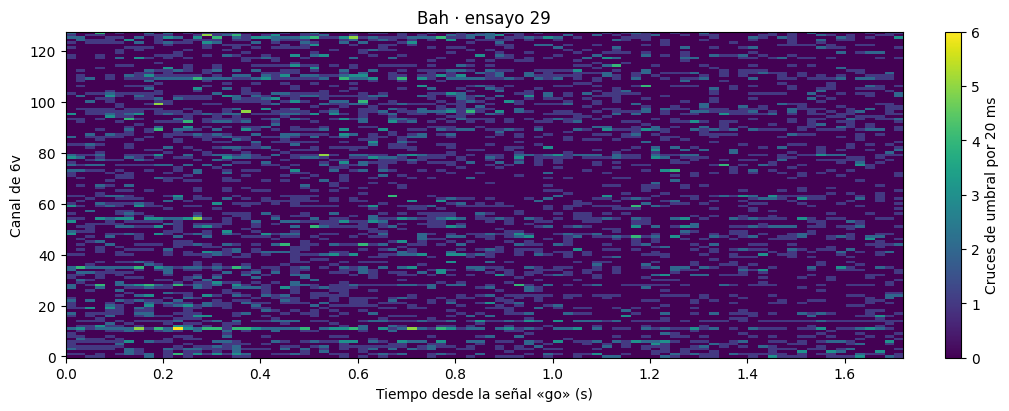

In [5]:
import matplotlib.pyplot as plt

duracion = ensayo_tx1.shape[0] * 0.02

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)

mapa = ax.imshow(
    ensayo_tx1[:, :128].T,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    extent=(0, duracion, -0.5, 127.5),
    cmap="viridis",
)

ax.set(
    xlabel="Tiempo desde la señal «go» (s)",
    ylabel="Canal de 6v",
    title=f"Bah · ensayo {indice_ensayo}",
)

fig.colorbar(mapa, ax=ax, label="Cruces de umbral por 20 ms")
plt.show()

comparamos los 16 ensayos de Bah con los 16 de DO_NOTHING.

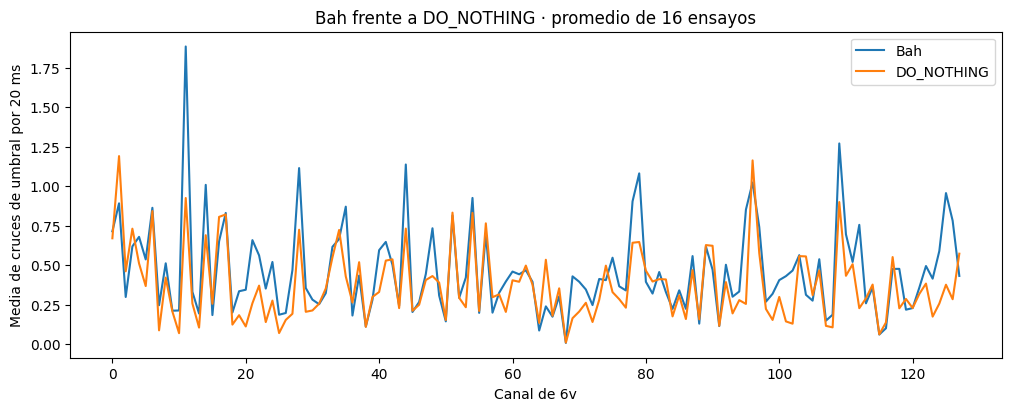

In [6]:
medias_por_condicion = {}

for condicion in ("Bah", "DO_NOTHING"):
    indices = np.flatnonzero(etiquetas == condicion)
    vectores = []

    for indice in indices:
        inicio, fin = np.asarray(
            senales["goTrialEpochs"][indice],
            dtype=int,
        )

        fragmento = senales["tx1"][inicio - 1:fin, :128]
        vectores.append(fragmento.mean(axis=0))

    medias_por_condicion[condicion] = np.stack(vectores)

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)

for condicion, matriz in medias_por_condicion.items():
    ax.plot(matriz.mean(axis=0), label=condicion)

ax.set(
    xlabel="Canal de 6v",
    ylabel="Media de cruces de umbral por 20 ms",
    title="Bah frente a DO_NOTHING · promedio de 16 ensayos",
)
ax.legend()
plt.show()

se parecen mucho , sospechosamente demasiado

hmmm

test cuanto varían sobre desviación estandard

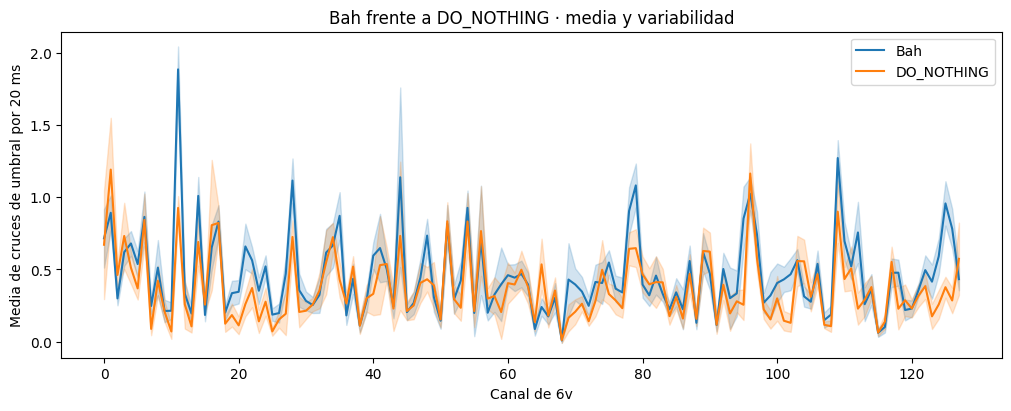

In [7]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)

for condicion, matriz in medias_por_condicion.items():
    media = matriz.mean(axis=0)
    desviacion = matriz.std(axis=0)
    canales = np.arange(media.size)

    linea, = ax.plot(canales, media, label=condicion)

    ax.fill_between(
        canales,
        media - desviacion,
        media + desviacion,
        color=linea.get_color(),
        alpha=0.2,
    )

ax.set(
    xlabel="Canal de 6v",
    ylabel="Media de cruces de umbral por 20 ms",
    title="Bah frente a DO_NOTHING · media y variabilidad",
)
ax.legend()
plt.show()

comparar bach y nothing frente a bah y pah

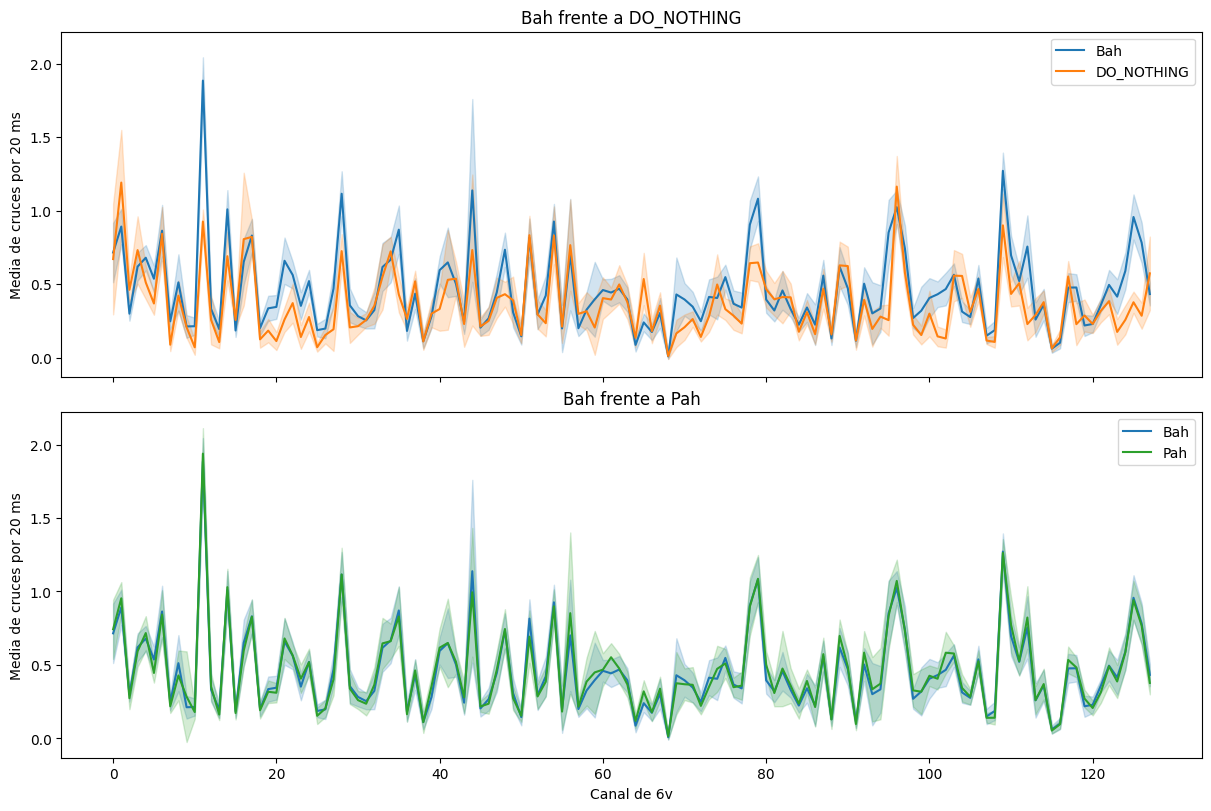

In [8]:
comparacion_fonemas = {}

for condicion in ("Bah", "DO_NOTHING", "Pah"):
    indices = np.flatnonzero(etiquetas == condicion)
    vectores = []

    for indice in indices:
        inicio, fin = np.asarray(
            senales["goTrialEpochs"][indice],
            dtype=int,
        )

        fragmento = senales["tx1"][inicio - 1:fin, :128]

        # Actividad media de cada canal durante este ensayo.
        vectores.append(fragmento.mean(axis=0))

    # Filas: ensayos. Columnas: canales.
    comparacion_fonemas[condicion] = np.stack(vectores)

comparaciones = [
    ("Bah", "DO_NOTHING"),
    ("Bah", "Pah"),
]

colores = {
    "Bah": "C0",
    "DO_NOTHING": "C1",
    "Pah": "C2",
}

fig_comparacion, ejes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, condiciones in zip(ejes, comparaciones):
    for condicion in condiciones:
        matriz = comparacion_fonemas[condicion]
        media = matriz.mean(axis=0)
        desviacion = matriz.std(axis=0)
        canales = np.arange(media.size)

        ax.plot(
            canales,
            media,
            label=condicion,
            color=colores[condicion],
        )

        ax.fill_between(
            canales,
            media - desviacion,
            media + desviacion,
            color=colores[condicion],
            alpha=0.2,
        )

    ax.set(
        title=f"{condiciones[0]} frente a {condiciones[1]}",
        ylabel="Media de cruces por 20 ms",
    )
    ax.legend()

ejes[-1].set_xlabel("Canal de 6v")
plt.show()

mapa de tiempo × canales por condición

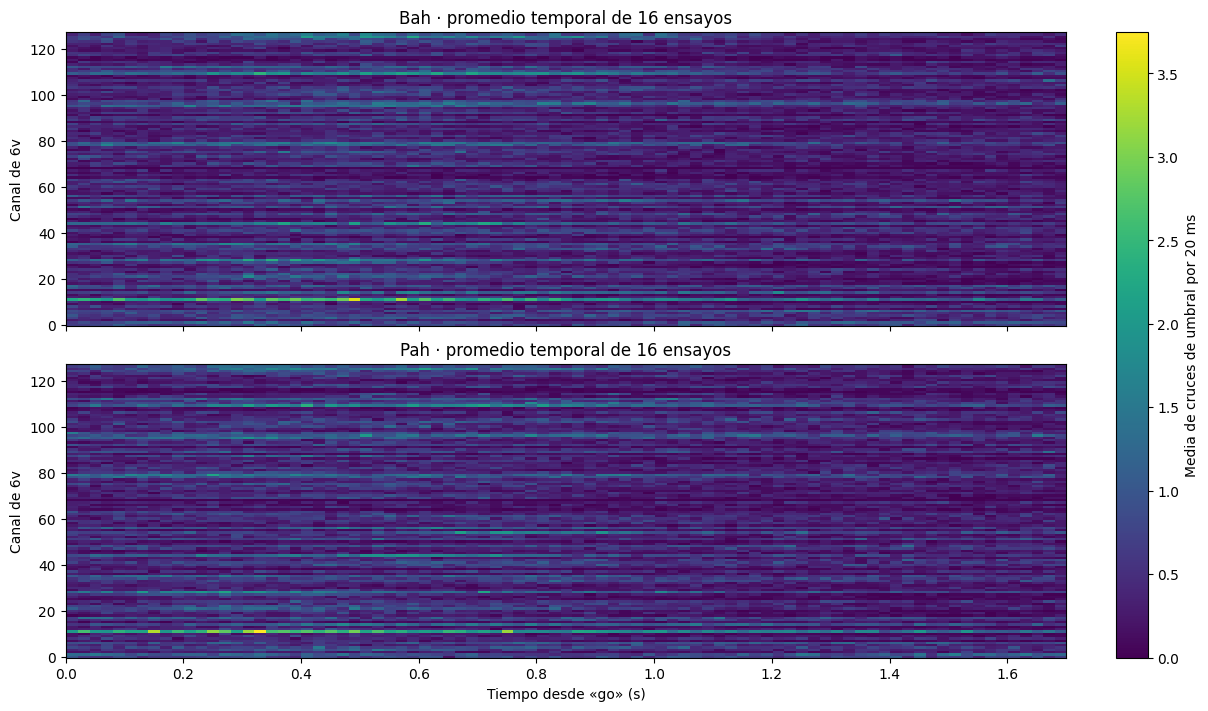

In [9]:
import numpy as np
import matplotlib.pyplot as plt

epocas_go = np.asarray(senales["goTrialEpochs"], dtype=int)

indices_comparacion = np.flatnonzero(
    np.isin(etiquetas, ("Bah", "Pah"))
)

limites = epocas_go[indices_comparacion]
longitudes = limites[:, 1] - limites[:, 0] + 1
bins_comunes = int(longitudes.min())

promedios_temporales = {}

for condicion in ("Bah", "Pah"):
    indices = np.flatnonzero(etiquetas == condicion)
    tramos = []

    for indice in indices:
        inicio = epocas_go[indice, 0] - 1

        fragmento = senales["tx1"][
            inicio:inicio + bins_comunes,
            :128,
        ]
        tramos.append(fragmento)

    # Forma: ensayos × tiempo × canales.
    repeticiones = np.stack(tramos)

    # Promediamos los ensayos y conservamos tiempo × canales.
    promedios_temporales[condicion] = repeticiones.mean(axis=0)

duracion_comun = bins_comunes * 0.02

# Ambos mapas utilizan la misma escala de color.
maximo = max(
    matriz.max() for matriz in promedios_temporales.values()
)

fig_temporal, ejes_temporales = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, condicion in zip(ejes_temporales, ("Bah", "Pah")):
    mapa = ax.imshow(
        promedios_temporales[condicion].T,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        extent=(0, duracion_comun, -0.5, 127.5),
        cmap="viridis",
        vmin=0,
        vmax=maximo,
    )

    ax.set(
        title=f"{condicion} · promedio temporal de 16 ensayos",
        ylabel="Canal de 6v",
    )

ejes_temporales[-1].set_xlabel("Tiempo desde «go» (s)")

fig_temporal.colorbar(
    mapa,
    ax=ejes_temporales,
    label="Media de cruces de umbral por 20 ms",
)

plt.show()

plot de diferencias , cuantoo puntos rojos difs pos y azules diffs negaticas

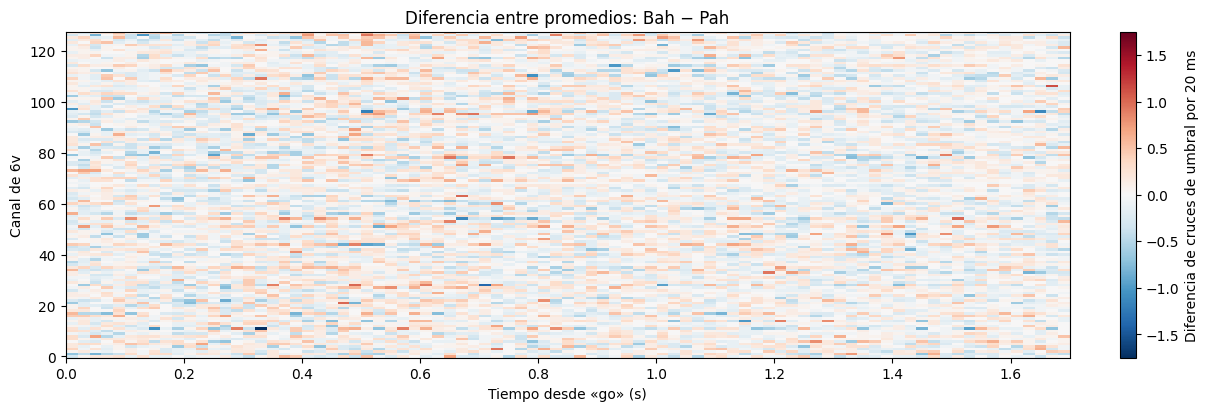

In [10]:
import numpy as np
import matplotlib.pyplot as plt

diferencia = (
    promedios_temporales["Bah"]
    - promedios_temporales["Pah"]
)

limite = float(np.abs(diferencia).max())
duracion = diferencia.shape[0] * 0.02

fig_diferencia, ax = plt.subplots(
    figsize=(12, 4),
    constrained_layout=True,
)

mapa = ax.imshow(
    diferencia.T,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    extent=(0, duracion, -0.5, diferencia.shape[1] - 0.5),
    cmap="RdBu_r",
    vmin=-limite,
    vmax=limite,
)

ax.set(
    xlabel="Tiempo desde «go» (s)",
    ylabel="Canal de 6v",
    title="Diferencia entre promedios: Bah − Pah",
)

fig_diferencia.colorbar(
    mapa,
    ax=ax,
    label="Diferencia de cruces de umbral por 20 ms",
)

plt.show()

## puede un clasificador sencillo distinguir un ensayo de Bah de uno de Pah?


muestras individuales: 32 ensayos × 128 características

In [11]:
datos_bloques = loadmat(
    archivo,
    variable_names=["blockNum"],
    simplify_cells=True,
)

bloque_por_bin = np.asarray(
    datos_bloques["blockNum"]
).reshape(-1).astype(int)

vectores = []
clases = []
bloques = []

indices = np.flatnonzero(
    np.isin(etiquetas, ("Bah", "Pah"))
)

for indice in indices:
    inicio_mat, fin_mat = np.asarray(
        senales["goTrialEpochs"][indice],
        dtype=int,
    )

    inicio = inicio_mat - 1
    fragmento = senales["tx1"][inicio:fin_mat, :128]

    vectores.append(fragmento.mean(axis=0))
    clases.append(etiquetas[indice])
    bloques.append(bloque_por_bin[inicio])

X_fonemas = np.stack(vectores)
y_fonemas = np.asarray(clases)
bloques_fonemas = np.asarray(bloques)

print("X — ensayos × características:", X_fonemas.shape)
print("y — etiquetas:", y_fonemas.shape)
print("Bloques:", np.unique(bloques_fonemas))

X — ensayos × características: (32, 128)
y — etiquetas: (32,)
Bloques: [17 18 19 20 21 22 23 24]


clasificador que calcula un vector medio por clase, (centroide) , y asigna cada ensayo al centroide más cercano.

In [12]:
import yaml

cfg_fonemas = yaml.safe_load(
    (raiz / "configs" / "fonemas_centroides.yaml").read_text()
)

mascara_train = np.isin(
    bloques_fonemas,
    cfg_fonemas["particiones"]["train"],
)

mascara_val = np.isin(
    bloques_fonemas,
    cfg_fonemas["particiones"]["validacion"],
)

if np.any(mascara_train & mascara_val):
    raise ValueError("Hay bloques compartidos entre train y validación.")

if not np.all(mascara_train | mascara_val):
    raise ValueError("Hay ensayos sin partición asignada.")

X_train = X_fonemas[mascara_train]
y_train = y_fonemas[mascara_train]

X_val = X_fonemas[mascara_val]
y_val = y_fonemas[mascara_val]

print("Train:", X_train.shape)
print("Validación:", X_val.shape)

for condicion in np.unique(y_fonemas):
    print(
        condicion,
        "→ train:", np.count_nonzero(y_train == condicion),
        "| validación:", np.count_nonzero(y_val == condicion),
    )

Train: (24, 128)
Validación: (8, 128)
Bah → train: 12 | validación: 4
Pah → train: 12 | validación: 4


In [13]:
import sys
from time import perf_counter
import numpy as np

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.utils.seed import fijar_seed
from src.utils.tracking import abrir_run, registrar

if cfg_fonemas["modelo"]["nombre"] != "centroides_euclideos":
    raise ValueError("Esta celda implementa centroides euclídeos.")

fijar_seed(cfg_fonemas["experimento"]["seed"])

run = abrir_run(cfg_fonemas)
if run is None:
    raise RuntimeError("El entrenamiento necesita un registro de W&B.")

with run:
    run.config.update({
        "archivo_datos": archivo.relative_to(raiz).as_posix(),
        "representacion": "media_tx1_go_6v",
        "muestras_train": int(X_train.shape[0]),
        "muestras_validacion": int(X_val.shape[0]),
        "hardware_modelo": "CPU con NumPy",
    })

    inicio_ajuste = perf_counter()

    if cfg_fonemas["modelo"]["estandarizar"]:
        media_train = X_train.mean(axis=0)
        escala_train = X_train.std(axis=0)

        # Evitamos dividir por cero en canales constantes.
        escala_train = np.where(escala_train == 0, 1.0, escala_train)
    else:
        media_train = np.zeros(X_train.shape[1])
        escala_train = np.ones(X_train.shape[1])

    X_train_norm = (X_train - media_train) / escala_train

    clases_modelo = np.unique(y_train)
    centroides = np.stack([
        X_train_norm[y_train == clase].mean(axis=0)
        for clase in clases_modelo
    ])

    tiempo_ajuste = perf_counter() - inicio_ajuste

    inicio_validacion = perf_counter()

    # Aplicamos las estadísticas aprendidas en train.
    X_val_norm = (X_val - media_train) / escala_train

    # Una distancia por ensayo y por centroide.
    distancias = (
        X_val_norm[:, None, :] - centroides[None, :, :]
    ) ** 2
    distancias = distancias.sum(axis=2)

    predicciones_val = clases_modelo[distancias.argmin(axis=1)]
    tiempo_validacion = perf_counter() - inicio_validacion

    aciertos = int(np.count_nonzero(predicciones_val == y_val))
    accuracy_val = aciertos / len(y_val)

    registrar(run, {
        "val/accuracy": accuracy_val,
        "val/aciertos": aciertos,
        "tiempos/ajuste_s": tiempo_ajuste,
        "tiempos/validacion_s": tiempo_validacion,
    })

    print("Centroides:", centroides.shape)
    print(f"Accuracy de validación: {accuracy_val:.1%}")
    print(f"Aciertos: {aciertos}/{len(y_val)}")
    print(f"Tiempo de ajuste: {tiempo_ajuste:.6f} s")
    print()

    for real, predicha in zip(y_val, predicciones_val):
        print(f"Real: {real} | Predicción: {predicha}")

wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


Centroides: (2, 128)
Accuracy de validación: 87.5%
Aciertos: 7/8
Tiempo de ajuste: 0.000250 s

Real: Bah | Predicción: Bah
Real: Pah | Predicción: Pah
Real: Pah | Predicción: Pah
Real: Bah | Predicción: Bah
Real: Bah | Predicción: Bah
Real: Pah | Predicción: Bah
Real: Pah | Predicción: Pah
Real: Bah | Predicción: Bah


wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


ha acertado 7 de 8 , aunque con tan pocos ejemplos no podemos asegurar nada

In [14]:
import sys
from time import perf_counter

import numpy as np
import yaml

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.utils.seed import fijar_seed
from src.utils.tracking import abrir_run, registrar

cfg_cv = yaml.safe_load(
    (raiz / "configs" / "fonemas_centroides_cv.yaml").read_text(
        encoding="utf-8"
    )
)

if cfg_cv["validacion"]["metodo"] != "dejar_un_bloque_fuera":
    raise ValueError("Esta celda deja fuera un bloque en cada repetición.")

if cfg_cv["modelo"]["nombre"] != "centroides_euclideos":
    raise ValueError("Esta celda implementa centroides euclídeos.")

bloques_cv = np.asarray(cfg_cv["validacion"]["bloques"], dtype=int)

# Cada bloque debe aparecer exactamente una vez en la configuración.
if not np.array_equal(
    np.sort(bloques_cv),
    np.unique(bloques_fonemas),
):
    raise ValueError("Los bloques configurados no coinciden con los datos.")

fijar_seed(cfg_cv["experimento"]["seed"])

# Guardaremos cada predicción en la posición de su ensayo original.
predicciones_cv = np.empty_like(y_fonemas)
resultados_cv = []

run_cv = abrir_run(cfg_cv)
if run_cv is None:
    raise RuntimeError("El entrenamiento necesita un registro de W&B.")

with run_cv:
    run_cv.config.update({
        "archivo_datos": archivo.relative_to(raiz).as_posix(),
        "representacion": "media_tx1_go_6v",
        "muestras": int(len(y_fonemas)),
        "caracteristicas": int(X_fonemas.shape[1]),
        "hardware_modelo": "CPU con NumPy",
    })

    for bloque_cv in bloques_cv:
        # El bloque elegido se reserva entero para validación.
        mascara_val_cv = bloques_fonemas == bloque_cv
        mascara_train_cv = ~mascara_val_cv

        X_train_cv = X_fonemas[mascara_train_cv]
        y_train_cv = y_fonemas[mascara_train_cv]
        X_val_cv = X_fonemas[mascara_val_cv]
        y_val_cv = y_fonemas[mascara_val_cv]

        inicio_ajuste_cv = perf_counter()

        if cfg_cv["modelo"]["estandarizar"]:
            media_cv = X_train_cv.mean(axis=0)
            escala_cv = X_train_cv.std(axis=0)
            escala_cv = np.where(escala_cv == 0, 1.0, escala_cv)
        else:
            media_cv = np.zeros(X_train_cv.shape[1])
            escala_cv = np.ones(X_train_cv.shape[1])

        X_train_norm_cv = (X_train_cv - media_cv) / escala_cv

        clases_cv = np.unique(y_train_cv)
        centroides_cv = np.stack([
            X_train_norm_cv[y_train_cv == clase].mean(axis=0)
            for clase in clases_cv
        ])

        tiempo_ajuste_cv = perf_counter() - inicio_ajuste_cv

        # Validación usa las estadísticas de este entrenamiento.
        X_val_norm_cv = (X_val_cv - media_cv) / escala_cv

        distancias_cv = (
            X_val_norm_cv[:, None, :] - centroides_cv[None, :, :]
        ) ** 2
        distancias_cv = distancias_cv.sum(axis=2)

        predichas_cv = clases_cv[distancias_cv.argmin(axis=1)]
        predicciones_cv[mascara_val_cv] = predichas_cv

        aciertos_bloque_cv = int(
            np.count_nonzero(predichas_cv == y_val_cv)
        )
        total_bloque_cv = len(y_val_cv)
        accuracy_bloque_cv = aciertos_bloque_cv / total_bloque_cv

        resultados_cv.append({
            "bloque": int(bloque_cv),
            "aciertos": aciertos_bloque_cv,
            "total": total_bloque_cv,
            "accuracy": accuracy_bloque_cv,
            "ajuste_s": tiempo_ajuste_cv,
        })

        registrar(run_cv, {
            "cv/bloque": int(bloque_cv),
            "cv/accuracy_bloque": accuracy_bloque_cv,
            "cv/aciertos_bloque": aciertos_bloque_cv,
            "cv/muestras_train": int(len(y_train_cv)),
            "cv/muestras_validacion": int(total_bloque_cv),
            "cv/ajuste_bloque_s": tiempo_ajuste_cv,
        })

        print(
            f"Bloque fuera: {bloque_cv} | "
            f"Aciertos: {aciertos_bloque_cv}/{total_bloque_cv} | "
            f"Accuracy: {accuracy_bloque_cv:.1%}"
        )

    # Cada ensayo aporta una única predicción de validación.
    aciertos_total_cv = int(
        np.count_nonzero(predicciones_cv == y_fonemas)
    )
    accuracy_total_cv = aciertos_total_cv / len(y_fonemas)
    tiempo_ajuste_total_cv = sum(
        resultado["ajuste_s"] for resultado in resultados_cv
    )

    registrar(run_cv, {
        "cv/accuracy_total": accuracy_total_cv,
        "cv/aciertos_total": aciertos_total_cv,
        "cv/ensayos_evaluados": int(len(y_fonemas)),
        "cv/ajuste_total_s": tiempo_ajuste_total_cv,
    })

    print()
    print(f"Accuracy conjunta: {accuracy_total_cv:.1%}")
    print(f"Aciertos totales: {aciertos_total_cv}/{len(y_fonemas)}")
    print(f"Tiempo de los ocho ajustes: {tiempo_ajuste_total_cv:.6f} s")

wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


Bloque fuera: 17 | Aciertos: 2/4 | Accuracy: 50.0%
Bloque fuera: 18 | Aciertos: 3/4 | Accuracy: 75.0%
Bloque fuera: 19 | Aciertos: 3/4 | Accuracy: 75.0%
Bloque fuera: 20 | Aciertos: 3/4 | Accuracy: 75.0%
Bloque fuera: 21 | Aciertos: 2/4 | Accuracy: 50.0%
Bloque fuera: 22 | Aciertos: 3/4 | Accuracy: 75.0%
Bloque fuera: 23 | Aciertos: 4/4 | Accuracy: 100.0%
Bloque fuera: 24 | Aciertos: 2/4 | Accuracy: 50.0%

Accuracy conjunta: 68.8%
Aciertos totales: 22/32
Tiempo de los ocho ajustes: 0.001389 s


wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


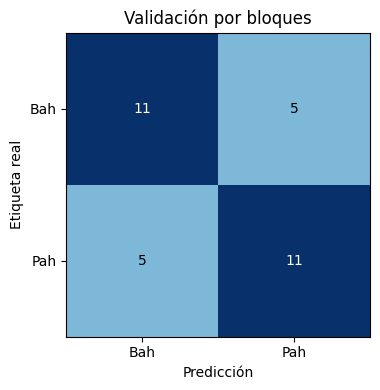

In [15]:
import numpy as np
import matplotlib.pyplot as plt

clases_confusion_cv = np.unique(y_fonemas)

matriz_confusion_cv = np.array([
    [
        np.count_nonzero(
            (y_fonemas == real) & (predicciones_cv == predicha)
        )
        for predicha in clases_confusion_cv
    ]
    for real in clases_confusion_cv
])

fig_confusion_cv, ax_confusion_cv = plt.subplots(figsize=(4, 4))

ax_confusion_cv.imshow(matriz_confusion_cv, cmap="Blues", vmin=0)

ax_confusion_cv.set_xticks(
    range(len(clases_confusion_cv)),
    labels=clases_confusion_cv,
)
ax_confusion_cv.set_yticks(
    range(len(clases_confusion_cv)),
    labels=clases_confusion_cv,
)
ax_confusion_cv.set_xlabel("Predicción")
ax_confusion_cv.set_ylabel("Etiqueta real")
ax_confusion_cv.set_title("Validación por bloques")

for fila in range(len(clases_confusion_cv)):
    for columna in range(len(clases_confusion_cv)):
        valor = matriz_confusion_cv[fila, columna]
        color = (
            "white"
            if valor > matriz_confusion_cv.max() / 2
            else "black"
        )
        ax_confusion_cv.text(
            columna, fila, str(valor),
            ha="center", va="center", color=color,
        )

fig_confusion_cv.tight_layout()
plt.show()

In [16]:
import numpy as np
from scipy.io import loadmat

archivo_26 = (
    raiz / "data" / "speech_2023" / "tuningTasks"
    / "t12.2022.04.26_phonemes.mat"
)

datos_26 = loadmat(
    archivo_26,
    variable_names=["tx1", "goTrialEpochs", "cueList", "trialCues"],
    simplify_cells=True,
)

# Convertimos los identificadores de MATLAB en etiquetas.
lista_cues_26 = np.asarray(datos_26["cueList"]).reshape(-1)
ids_cues_26 = np.asarray(
    datos_26["trialCues"]
).reshape(-1).astype(int)

etiquetas_26 = lista_cues_26[ids_cues_26 - 1]
epocas_26 = np.asarray(datos_26["goTrialEpochs"], dtype=int)

# Seleccionamos las mismas condiciones y canales que antes.
condiciones_26 = np.unique(y_fonemas)
numero_canales_26 = X_fonemas.shape[1]

indices_26 = np.flatnonzero(
    np.isin(etiquetas_26, condiciones_26)
)

vectores_26 = []

for indice_26 in indices_26:
    inicio_mat_26, fin_mat_26 = epocas_26[indice_26]

    fragmento_26 = datos_26["tx1"][
        inicio_mat_26 - 1:fin_mat_26,
        :numero_canales_26,
    ]

    # Una media temporal por canal para este ensayo.
    vectores_26.append(fragmento_26.mean(axis=0))

X_26 = np.stack(vectores_26)
y_26 = etiquetas_26[indices_26]

print("Archivo:", archivo_26.name)
print("X — ensayos × características:", X_26.shape)
print("y — etiquetas:", y_26.shape)

for condicion_26 in condiciones_26:
    print(
        condicion_26,
        "→",
        np.count_nonzero(y_26 == condicion_26),
        "ensayos",
    )

Archivo: t12.2022.04.26_phonemes.mat
X — ensayos × características: (40, 128)
y — etiquetas: (40,)
Bah → 20 ensayos
Pah → 20 ensayos


In [17]:
import sys
from time import perf_counter

import numpy as np
import yaml

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.utils.seed import fijar_seed
from src.utils.tracking import abrir_run, registrar

cfg_dias = yaml.safe_load(
    (raiz / "configs" / "fonemas_centroides_otro_dia.yaml").read_text(
        encoding="utf-8"
    )
)

if cfg_dias["modelo"]["nombre"] != "centroides_euclideos":
    raise ValueError("Esta celda implementa centroides euclídeos.")

# Comprobamos que las matrices proceden de los archivos configurados.
if archivo.resolve() != (
    raiz / cfg_dias["datos"]["entrenamiento"]
).resolve():
    raise ValueError("El archivo de entrenamiento no coincide.")

if archivo_26.resolve() != (
    raiz / cfg_dias["datos"]["evaluacion"]
).resolve():
    raise ValueError("El archivo de evaluación no coincide.")

if X_fonemas.shape[1] != X_26.shape[1]:
    raise ValueError("Las dos sesiones deben tener las mismas características.")

fijar_seed(cfg_dias["experimento"]["seed"])

run_dias = abrir_run(cfg_dias)
if run_dias is None:
    raise RuntimeError("El entrenamiento necesita un registro de W&B.")

with run_dias:
    run_dias.config.update({
        "representacion": "media_tx1_go_6v",
        "muestras_train": int(len(y_fonemas)),
        "muestras_evaluacion": int(len(y_26)),
        "hardware_modelo": "CPU con NumPy",
    })

    inicio_ajuste_dias = perf_counter()

    # Aprendemos la normalización con todos los ensayos del día 21.
    if cfg_dias["modelo"]["estandarizar"]:
        media_dia21 = X_fonemas.mean(axis=0)
        escala_dia21 = X_fonemas.std(axis=0)
        escala_dia21 = np.where(
            escala_dia21 == 0, 1.0, escala_dia21
        )
    else:
        media_dia21 = np.zeros(X_fonemas.shape[1])
        escala_dia21 = np.ones(X_fonemas.shape[1])

    X_dia21_norm = (X_fonemas - media_dia21) / escala_dia21

    clases_dias = np.unique(y_fonemas)
    centroides_dia21 = np.stack([
        X_dia21_norm[y_fonemas == clase].mean(axis=0)
        for clase in clases_dias
    ])

    tiempo_ajuste_dias = perf_counter() - inicio_ajuste_dias

    inicio_evaluacion_dias = perf_counter()

    # Aplicamos al día 26 las estadísticas del día 21.
    X_dia26_norm = (X_26 - media_dia21) / escala_dia21

    distancias_dias = (
        X_dia26_norm[:, None, :] - centroides_dia21[None, :, :]
    ) ** 2
    distancias_dias = distancias_dias.sum(axis=2)

    predicciones_26 = clases_dias[distancias_dias.argmin(axis=1)]

    tiempo_evaluacion_dias = (
        perf_counter() - inicio_evaluacion_dias
    )

    aciertos_dias = int(
        np.count_nonzero(predicciones_26 == y_26)
    )
    accuracy_dias = aciertos_dias / len(y_26)

    metricas_dias = {
        "eval/accuracy": accuracy_dias,
        "eval/aciertos": aciertos_dias,
        "tiempos/ajuste_s": tiempo_ajuste_dias,
        "tiempos/evaluacion_s": tiempo_evaluacion_dias,
    }

    print("Entrenamiento — día 21:", X_fonemas.shape)
    print("Evaluación — día 26:", X_26.shape)
    print(f"Accuracy en otro día: {accuracy_dias:.1%}")
    print(f"Aciertos: {aciertos_dias}/{len(y_26)}")
    print(f"Tiempo de ajuste: {tiempo_ajuste_dias:.6f} s")
    print()

    for clase_dias in clases_dias:
        mascara_clase_dias = y_26 == clase_dias
        total_clase_dias = int(mascara_clase_dias.sum())
        aciertos_clase_dias = int(np.count_nonzero(
            predicciones_26[mascara_clase_dias] == clase_dias
        ))

        metricas_dias[f"eval/{clase_dias}/accuracy"] = (
            aciertos_clase_dias / total_clase_dias
        )

        print(
            f"{clase_dias} → "
            f"{aciertos_clase_dias}/{total_clase_dias} aciertos"
        )

    registrar(run_dias, metricas_dias)

wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


Entrenamiento — día 21: (32, 128)
Evaluación — día 26: (40, 128)
Accuracy en otro día: 52.5%
Aciertos: 21/40
Tiempo de ajuste: 0.000263 s

Bah → 20/20 aciertos
Pah → 1/20 aciertos


wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


en este día el modelo predice siempre bah 39/40



In [18]:
datos_bloques_26 = loadmat(
    archivo_26,
    variable_names=["blockNum"],
    simplify_cells=True,
)

bloque_por_bin_26 = np.asarray(
    datos_bloques_26["blockNum"]
).reshape(-1).astype(int)

# El bloque se identifica usando el primer bin del ensayo.
inicios_26 = epocas_26[indices_26, 0] - 1
bloques_26 = bloque_por_bin_26[inicios_26]

print("Bloques:", np.unique(bloques_26))

for bloque_26 in np.unique(bloques_26):
    etiquetas_bloque_26 = y_26[bloques_26 == bloque_26]

    print(
        f"Bloque {bloque_26} | "
        f"Bah: {np.count_nonzero(etiquetas_bloque_26 == 'Bah')} | "
        f"Pah: {np.count_nonzero(etiquetas_bloque_26 == 'Pah')}"
    )

Bloques: [ 2  3  4  5  6  7  8  9 10 11]
Bloque 2 | Bah: 2 | Pah: 2
Bloque 3 | Bah: 2 | Pah: 2
Bloque 4 | Bah: 2 | Pah: 2
Bloque 5 | Bah: 2 | Pah: 2
Bloque 6 | Bah: 2 | Pah: 2
Bloque 7 | Bah: 2 | Pah: 2
Bloque 8 | Bah: 2 | Pah: 2
Bloque 9 | Bah: 2 | Pah: 2
Bloque 10 | Bah: 2 | Pah: 2
Bloque 11 | Bah: 2 | Pah: 2


test con diez repeticiones, cada una con 36 ensayos para entrenar y 4 para validar. En cada repetición aprendemos la normalización y los centroides con esos 36 ensayos.

In [19]:
import sys
from time import perf_counter

import numpy as np
import yaml

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.utils.seed import fijar_seed
from src.utils.tracking import abrir_run, registrar

cfg_cv_26 = yaml.safe_load(
    (raiz / "configs" / "fonemas_centroides_cv_26.yaml").read_text(
        encoding="utf-8"
    )
)

if cfg_cv_26["validacion"]["metodo"] != "dejar_un_bloque_fuera":
    raise ValueError("Esta celda deja fuera un bloque en cada repetición.")

if cfg_cv_26["modelo"]["nombre"] != "centroides_euclideos":
    raise ValueError("Esta celda implementa centroides euclídeos.")

lista_bloques_cv_26 = np.asarray(
    cfg_cv_26["validacion"]["bloques"],
    dtype=int,
)

if not np.array_equal(
    np.sort(lista_bloques_cv_26),
    np.unique(bloques_26),
):
    raise ValueError("Los bloques configurados no coinciden con los datos.")

fijar_seed(cfg_cv_26["experimento"]["seed"])

predicciones_cv_26 = np.empty_like(y_26)
resultados_cv_26 = []

run_cv_26 = abrir_run(cfg_cv_26)
if run_cv_26 is None:
    raise RuntimeError("El entrenamiento necesita un registro de W&B.")

with run_cv_26:
    run_cv_26.config.update({
        "archivo_datos": archivo_26.relative_to(raiz).as_posix(),
        "representacion": "media_tx1_go_6v",
        "muestras": int(len(y_26)),
        "caracteristicas": int(X_26.shape[1]),
        "hardware_modelo": "CPU con NumPy",
    })

    for bloque_cv_26 in lista_bloques_cv_26:
        mascara_val_cv_26 = bloques_26 == bloque_cv_26
        mascara_train_cv_26 = ~mascara_val_cv_26

        X_train_cv_26 = X_26[mascara_train_cv_26]
        y_train_cv_26 = y_26[mascara_train_cv_26]
        X_val_cv_26 = X_26[mascara_val_cv_26]
        y_val_cv_26 = y_26[mascara_val_cv_26]

        inicio_ajuste_cv_26 = perf_counter()

        # La normalización se aprende con el entrenamiento de este bloque.
        if cfg_cv_26["modelo"]["estandarizar"]:
            media_cv_26 = X_train_cv_26.mean(axis=0)
            escala_cv_26 = X_train_cv_26.std(axis=0)
            escala_cv_26 = np.where(
                escala_cv_26 == 0, 1.0, escala_cv_26
            )
        else:
            media_cv_26 = np.zeros(X_train_cv_26.shape[1])
            escala_cv_26 = np.ones(X_train_cv_26.shape[1])

        X_train_norm_cv_26 = (
            X_train_cv_26 - media_cv_26
        ) / escala_cv_26

        clases_cv_26 = np.unique(y_train_cv_26)
        centroides_cv_26 = np.stack([
            X_train_norm_cv_26[y_train_cv_26 == clase].mean(axis=0)
            for clase in clases_cv_26
        ])

        tiempo_ajuste_cv_26 = (
            perf_counter() - inicio_ajuste_cv_26
        )

        # Aplicamos esas mismas estadísticas a la validación.
        X_val_norm_cv_26 = (
            X_val_cv_26 - media_cv_26
        ) / escala_cv_26

        distancias_cv_26 = (
            X_val_norm_cv_26[:, None, :]
            - centroides_cv_26[None, :, :]
        ) ** 2
        distancias_cv_26 = distancias_cv_26.sum(axis=2)

        predichas_cv_26 = clases_cv_26[
            distancias_cv_26.argmin(axis=1)
        ]
        predicciones_cv_26[mascara_val_cv_26] = predichas_cv_26

        aciertos_bloque_cv_26 = int(
            np.count_nonzero(predichas_cv_26 == y_val_cv_26)
        )
        total_bloque_cv_26 = len(y_val_cv_26)
        accuracy_bloque_cv_26 = (
            aciertos_bloque_cv_26 / total_bloque_cv_26
        )

        resultados_cv_26.append({
            "bloque": int(bloque_cv_26),
            "aciertos": aciertos_bloque_cv_26,
            "total": total_bloque_cv_26,
            "accuracy": accuracy_bloque_cv_26,
            "ajuste_s": tiempo_ajuste_cv_26,
        })

        registrar(run_cv_26, {
            "cv/bloque": int(bloque_cv_26),
            "cv/accuracy_bloque": accuracy_bloque_cv_26,
            "cv/aciertos_bloque": aciertos_bloque_cv_26,
            "cv/muestras_train": int(len(y_train_cv_26)),
            "cv/muestras_validacion": int(total_bloque_cv_26),
            "cv/ajuste_bloque_s": tiempo_ajuste_cv_26,
        })

        print(
            f"Bloque fuera: {bloque_cv_26} | "
            f"Aciertos: {aciertos_bloque_cv_26}/{total_bloque_cv_26} | "
            f"Accuracy: {accuracy_bloque_cv_26:.1%}"
        )

    aciertos_total_cv_26 = int(
        np.count_nonzero(predicciones_cv_26 == y_26)
    )
    accuracy_total_cv_26 = aciertos_total_cv_26 / len(y_26)
    tiempo_total_cv_26 = sum(
        resultado["ajuste_s"] for resultado in resultados_cv_26
    )

    metricas_cv_26 = {
        "cv/accuracy_total": accuracy_total_cv_26,
        "cv/aciertos_total": aciertos_total_cv_26,
        "cv/ensayos_evaluados": int(len(y_26)),
        "cv/ajuste_total_s": tiempo_total_cv_26,
    }

    print()
    print(f"Accuracy conjunta: {accuracy_total_cv_26:.1%}")
    print(f"Aciertos totales: {aciertos_total_cv_26}/{len(y_26)}")
    print(f"Tiempo de los diez ajustes: {tiempo_total_cv_26:.6f} s")
    print()

    for clase_cv_26 in np.unique(y_26):
        mascara_clase_cv_26 = y_26 == clase_cv_26
        total_clase_cv_26 = int(mascara_clase_cv_26.sum())
        aciertos_clase_cv_26 = int(np.count_nonzero(
            predicciones_cv_26[mascara_clase_cv_26] == clase_cv_26
        ))

        metricas_cv_26[f"cv/{clase_cv_26}/accuracy"] = (
            aciertos_clase_cv_26 / total_clase_cv_26
        )

        print(
            f"{clase_cv_26} → "
            f"{aciertos_clase_cv_26}/{total_clase_cv_26} aciertos"
        )

    registrar(run_cv_26, metricas_cv_26)

wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


Bloque fuera: 2 | Aciertos: 2/4 | Accuracy: 50.0%
Bloque fuera: 3 | Aciertos: 3/4 | Accuracy: 75.0%
Bloque fuera: 4 | Aciertos: 2/4 | Accuracy: 50.0%
Bloque fuera: 5 | Aciertos: 3/4 | Accuracy: 75.0%
Bloque fuera: 6 | Aciertos: 4/4 | Accuracy: 100.0%
Bloque fuera: 7 | Aciertos: 4/4 | Accuracy: 100.0%
Bloque fuera: 8 | Aciertos: 4/4 | Accuracy: 100.0%
Bloque fuera: 9 | Aciertos: 3/4 | Accuracy: 75.0%
Bloque fuera: 10 | Aciertos: 4/4 | Accuracy: 100.0%
Bloque fuera: 11 | Aciertos: 4/4 | Accuracy: 100.0%

Accuracy conjunta: 82.5%
Aciertos totales: 33/40
Tiempo de los diez ajustes: 0.001708 s

Bah → 17/20 aciertos
Pah → 16/20 aciertos


wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


Puede que la actividad registrada cambie entre días y por eso el modelo del 21 funcione peor en el 26. Como al entrenar dentro del día 26 mejora, voy a pobar si unos pocos ensayos de calibración ayudan a adaptarlo.

In [22]:
import sys
from time import perf_counter

import numpy as np
import yaml

necesarias_cal = (
    "raiz", "X_fonemas", "y_fonemas",
    "X_26", "y_26", "bloques_26",
    "archivo", "archivo_26",
)
faltan_cal = [
    nombre for nombre in necesarias_cal
    if nombre not in globals()
]

if faltan_cal:
    raise RuntimeError(
        "Ejecuta primero las celdas que preparan los datos y bloques. "
        f"Faltan: {', '.join(faltan_cal)}"
    )

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.utils.seed import fijar_seed
from src.utils.tracking import abrir_run, registrar

cfg_cal = yaml.safe_load(
    (raiz / "configs" / "fonemas_calibracion.yaml").read_text(
        encoding="utf-8"
    )
)

if cfg_cal["modelo"]["nombre"] != "centroides_euclideos":
    raise ValueError("Esta celda implementa centroides euclídeos.")

mascara_cal = np.isin(
    bloques_26, cfg_cal["particiones"]["calibracion"]
)
mascara_eval_cal = np.isin(
    bloques_26, cfg_cal["particiones"]["evaluacion"]
)

if np.any(mascara_cal & mascara_eval_cal):
    raise ValueError("Calibración y evaluación comparten ensayos.")

if not np.all(mascara_cal | mascara_eval_cal):
    raise ValueError("Hay ensayos sin partición asignada.")

if not mascara_cal.any() or not mascara_eval_cal.any():
    raise ValueError("Las dos particiones deben contener ensayos.")

X_cal = X_26[mascara_cal]
X_eval_cal = X_26[mascara_eval_cal]
y_eval_cal = y_26[mascara_eval_cal]

fijar_seed(cfg_cal["experimento"]["seed"])

run_cal = abrir_run(cfg_cal)
if run_cal is None:
    raise RuntimeError("El experimento necesita un registro de W&B.")

with run_cal:
    run_cal.config.update({
        "archivo_train": archivo.relative_to(raiz).as_posix(),
        "archivo_nuevo_dia": archivo_26.relative_to(raiz).as_posix(),
        "representacion": "media_tx1_go_6v",
        "calibracion_metodo": "desplazamiento_media",
        "muestras_train": int(len(y_fonemas)),
        "muestras_calibracion": int(len(X_cal)),
        "muestras_evaluacion": int(len(y_eval_cal)),
        "hardware_modelo": "CPU con NumPy",
    })

    inicio_ajuste_cal = perf_counter()

    # Reconstruimos el modelo con los 32 ensayos del día 21.
    media_referencia_cal = X_fonemas.mean(axis=0)

    if cfg_cal["modelo"]["estandarizar"]:
        media_norm_cal = media_referencia_cal
        escala_norm_cal = X_fonemas.std(axis=0)
        escala_norm_cal = np.where(
            escala_norm_cal == 0, 1.0, escala_norm_cal
        )
    else:
        media_norm_cal = np.zeros(X_fonemas.shape[1])
        escala_norm_cal = np.ones(X_fonemas.shape[1])

    X_train_norm_cal = (
        X_fonemas - media_norm_cal
    ) / escala_norm_cal

    clases_cal = np.unique(y_fonemas)
    centroides_cal = np.stack([
        X_train_norm_cal[y_fonemas == clase].mean(axis=0)
        for clase in clases_cal
    ])

    tiempo_ajuste_cal = perf_counter() - inicio_ajuste_cal

    inicio_centrado_cal = perf_counter()

    # El desplazamiento se aprende únicamente con los 8 ensayos.
    media_nuevo_dia_cal = X_cal.mean(axis=0)
    desplazamiento_cal = (
        media_nuevo_dia_cal - media_referencia_cal
    )

    tiempo_centrado_cal = perf_counter() - inicio_centrado_cal

    versiones_cal = {
        "sin_calibrar": X_eval_cal,
        "calibrado": X_eval_cal - desplazamiento_cal,
    }

    predicciones_cal = {}
    accuracies_cal = {}
    metricas_cal = {
        "tiempos/ajuste_s": tiempo_ajuste_cal,
        "tiempos/calibracion_s": tiempo_centrado_cal,
    }

    print("Calibración:", X_cal.shape)
    print("Evaluación:", X_eval_cal.shape)

    for nombre_cal, X_version_cal in versiones_cal.items():
        X_version_norm_cal = (
            X_version_cal - media_norm_cal
        ) / escala_norm_cal

        distancias_cal = (
            X_version_norm_cal[:, None, :]
            - centroides_cal[None, :, :]
        ) ** 2
        distancias_cal = distancias_cal.sum(axis=2)

        predichas_cal = clases_cal[distancias_cal.argmin(axis=1)]
        predicciones_cal[nombre_cal] = predichas_cal

        aciertos_cal = int(
            np.count_nonzero(predichas_cal == y_eval_cal)
        )
        accuracy_cal = aciertos_cal / len(y_eval_cal)
        accuracies_cal[nombre_cal] = accuracy_cal

        metricas_cal[f"eval/{nombre_cal}/accuracy"] = accuracy_cal
        metricas_cal[f"eval/{nombre_cal}/aciertos"] = aciertos_cal

        print()
        print(
            f"{nombre_cal}: {aciertos_cal}/{len(y_eval_cal)} "
            f"→ {accuracy_cal:.1%}"
        )

        for clase_cal in clases_cal:
            mascara_clase_cal = y_eval_cal == clase_cal
            total_clase_cal = int(mascara_clase_cal.sum())
            aciertos_clase_cal = int(np.count_nonzero(
                predichas_cal[mascara_clase_cal] == clase_cal
            ))

            print(
                f"  {clase_cal}: "
                f"{aciertos_clase_cal}/{total_clase_cal}"
            )

    cambio_cal = (
        accuracies_cal["calibrado"]
        - accuracies_cal["sin_calibrar"]
    ) * 100

    metricas_cal["eval/cambio_puntos_porcentuales"] = cambio_cal
    registrar(run_cal, metricas_cal)

    print()
    print(f"Cambio: {cambio_cal:+.1f} puntos porcentuales")

wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


Calibración: (8, 128)
Evaluación: (32, 128)

sin_calibrar: 16/32 → 50.0%
  Bah: 16/16
  Pah: 0/16

calibrado: 16/32 → 50.0%
  Bah: 16/16
  Pah: 0/16

Cambio: +0.0 puntos porcentuales


wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


la media no mejora el resultado

In [26]:
import numpy as np
import yaml
from scipy.io import loadmat

cfg_4 = yaml.safe_load(
    (raiz / "configs" / "fonemas_4_clases.yaml").read_text(
        encoding="utf-8"
    )
)

archivo_4 = raiz / cfg_4["datos"]["archivo"]
senal_4 = cfg_4["datos"]["senal"]
canal_inicio_4, canal_fin_4 = cfg_4["datos"]["canales"]

datos_4 = loadmat(
    archivo_4,
    variable_names=[
        senal_4, "goTrialEpochs",
        "cueList", "trialCues", "blockNum",
    ],
    simplify_cells=True,
)

cues_4 = np.asarray(datos_4["cueList"]).reshape(-1)
ids_4 = np.asarray(
    datos_4["trialCues"]
).reshape(-1).astype(int)

etiquetas_4 = cues_4[ids_4 - 1]
epocas_4 = np.asarray(datos_4["goTrialEpochs"], dtype=int)
bloque_por_bin_4 = np.asarray(
    datos_4["blockNum"]
).reshape(-1).astype(int)

indices_4 = np.flatnonzero(
    np.isin(etiquetas_4, cfg_4["datos"]["condiciones"])
)

vectores_4 = []
lista_bloques_4 = []

for indice_4 in indices_4:
    inicio_mat_4, fin_mat_4 = epocas_4[indice_4]
    inicio_4 = inicio_mat_4 - 1

    fragmento_4 = datos_4[senal_4][
        inicio_4:fin_mat_4,
        canal_inicio_4:canal_fin_4,
    ]

    vectores_4.append(fragmento_4.mean(axis=0))
    lista_bloques_4.append(bloque_por_bin_4[inicio_4])

X_4 = np.stack(vectores_4)
y_4 = etiquetas_4[indices_4]
bloques_4 = np.asarray(lista_bloques_4)

print("X — ensayos × características:", X_4.shape)
print("y — etiquetas:", y_4.shape)
print("Bloques:", np.unique(bloques_4))

for condicion_4 in cfg_4["datos"]["condiciones"]:
    print(
        condicion_4,
        "→",
        np.count_nonzero(y_4 == condicion_4),
        "ensayos",
    )

X — ensayos × características: (80, 128)
y — etiquetas: (80,)
Bloques: [ 2  3  4  5  6  7  8  9 10 11]
Bah → 20 ensayos
Pah → 20 ensayos
Mah → 20 ensayos
Sah → 20 ensayos


test con un centroide por clase, calculado con los ensayos de entrenamiento de cada repetición

In [27]:
import sys
from time import perf_counter

import numpy as np

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.utils.seed import fijar_seed
from src.utils.tracking import abrir_run, registrar

if cfg_4["validacion"]["metodo"] != "dejar_un_bloque_fuera":
    raise ValueError("Esta celda deja fuera un bloque por repetición.")

if cfg_4["modelo"]["nombre"] != "centroides_euclideos":
    raise ValueError("Esta celda implementa centroides euclídeos.")

lista_bloques_cv_4 = np.asarray(
    cfg_4["validacion"]["bloques"], dtype=int
)

if not np.array_equal(
    np.sort(lista_bloques_cv_4),
    np.unique(bloques_4),
):
    raise ValueError("Los bloques configurados no coinciden con los datos.")

clases_modelo_4 = np.asarray(cfg_4["datos"]["condiciones"])

fijar_seed(cfg_4["experimento"]["seed"])

predicciones_cv_4 = np.empty_like(y_4)
resultados_cv_4 = []

run_4 = abrir_run(cfg_4)
if run_4 is None:
    raise RuntimeError("El entrenamiento necesita un registro de W&B.")

with run_4:
    run_4.config.update({
        "archivo_datos": archivo_4.relative_to(raiz).as_posix(),
        "representacion": "media_temporal_go",
        "muestras": int(len(y_4)),
        "caracteristicas": int(X_4.shape[1]),
        "hardware_modelo": "CPU con NumPy",
    })

    for bloque_cv_4 in lista_bloques_cv_4:
        mascara_val_cv_4 = bloques_4 == bloque_cv_4
        mascara_train_cv_4 = ~mascara_val_cv_4

        X_train_cv_4 = X_4[mascara_train_cv_4]
        y_train_cv_4 = y_4[mascara_train_cv_4]
        X_val_cv_4 = X_4[mascara_val_cv_4]
        y_val_cv_4 = y_4[mascara_val_cv_4]

        if not np.array_equal(
            np.sort(clases_modelo_4),
            np.unique(y_train_cv_4),
        ):
            raise ValueError("El entrenamiento debe contener todas las clases.")

        inicio_ajuste_cv_4 = perf_counter()

        # Estadísticas aprendidas solo con el entrenamiento.
        if cfg_4["modelo"]["estandarizar"]:
            media_cv_4 = X_train_cv_4.mean(axis=0)
            escala_cv_4 = X_train_cv_4.std(axis=0)
            escala_cv_4 = np.where(
                escala_cv_4 == 0, 1.0, escala_cv_4
            )
        else:
            media_cv_4 = np.zeros(X_train_cv_4.shape[1])
            escala_cv_4 = np.ones(X_train_cv_4.shape[1])

        X_train_norm_cv_4 = (
            X_train_cv_4 - media_cv_4
        ) / escala_cv_4

        # Un vector de 128 características por clase.
        centroides_cv_4 = np.stack([
            X_train_norm_cv_4[y_train_cv_4 == clase].mean(axis=0)
            for clase in clases_modelo_4
        ])

        tiempo_ajuste_cv_4 = perf_counter() - inicio_ajuste_cv_4

        X_val_norm_cv_4 = (
            X_val_cv_4 - media_cv_4
        ) / escala_cv_4

        # Distancia de cada ensayo a cada centroide.
        distancias_cv_4 = (
            X_val_norm_cv_4[:, None, :]
            - centroides_cv_4[None, :, :]
        ) ** 2
        distancias_cv_4 = distancias_cv_4.sum(axis=2)

        predichas_cv_4 = clases_modelo_4[
            distancias_cv_4.argmin(axis=1)
        ]
        predicciones_cv_4[mascara_val_cv_4] = predichas_cv_4

        aciertos_bloque_cv_4 = int(
            np.count_nonzero(predichas_cv_4 == y_val_cv_4)
        )
        total_bloque_cv_4 = len(y_val_cv_4)
        accuracy_bloque_cv_4 = (
            aciertos_bloque_cv_4 / total_bloque_cv_4
        )

        resultados_cv_4.append({
            "bloque": int(bloque_cv_4),
            "aciertos": aciertos_bloque_cv_4,
            "total": total_bloque_cv_4,
            "accuracy": accuracy_bloque_cv_4,
            "ajuste_s": tiempo_ajuste_cv_4,
        })

        registrar(run_4, {
            "cv/bloque": int(bloque_cv_4),
            "cv/accuracy_bloque": accuracy_bloque_cv_4,
            "cv/aciertos_bloque": aciertos_bloque_cv_4,
            "cv/muestras_train": int(len(y_train_cv_4)),
            "cv/muestras_validacion": int(total_bloque_cv_4),
            "cv/ajuste_bloque_s": tiempo_ajuste_cv_4,
        })

        print(
            f"Bloque fuera: {bloque_cv_4} | "
            f"Aciertos: {aciertos_bloque_cv_4}/{total_bloque_cv_4} | "
            f"Accuracy: {accuracy_bloque_cv_4:.1%}"
        )

    # Cada ensayo tiene una única predicción de validación.
    aciertos_total_cv_4 = int(
        np.count_nonzero(predicciones_cv_4 == y_4)
    )
    accuracy_total_cv_4 = aciertos_total_cv_4 / len(y_4)
    tiempo_total_cv_4 = sum(
        resultado["ajuste_s"] for resultado in resultados_cv_4
    )

    metricas_cv_4 = {
        "cv/accuracy_total": accuracy_total_cv_4,
        "cv/aciertos_total": aciertos_total_cv_4,
        "cv/ensayos_evaluados": int(len(y_4)),
        "cv/ajuste_total_s": tiempo_total_cv_4,
    }

    print()
    print(f"Accuracy conjunta: {accuracy_total_cv_4:.1%}")
    print(f"Aciertos totales: {aciertos_total_cv_4}/{len(y_4)}")
    print(f"Tiempo de los diez ajustes: {tiempo_total_cv_4:.6f} s")
    print()

    for clase_4 in clases_modelo_4:
        mascara_clase_4 = y_4 == clase_4
        total_clase_4 = int(mascara_clase_4.sum())
        aciertos_clase_4 = int(np.count_nonzero(
            predicciones_cv_4[mascara_clase_4] == clase_4
        ))

        metricas_cv_4[f"cv/{clase_4}/accuracy"] = (
            aciertos_clase_4 / total_clase_4
        )

        print(f"{clase_4} → {aciertos_clase_4}/{total_clase_4} aciertos")

    registrar(run_4, metricas_cv_4)

wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


Bloque fuera: 2 | Aciertos: 2/8 | Accuracy: 25.0%
Bloque fuera: 3 | Aciertos: 7/8 | Accuracy: 87.5%
Bloque fuera: 4 | Aciertos: 6/8 | Accuracy: 75.0%
Bloque fuera: 5 | Aciertos: 5/8 | Accuracy: 62.5%
Bloque fuera: 6 | Aciertos: 7/8 | Accuracy: 87.5%
Bloque fuera: 7 | Aciertos: 7/8 | Accuracy: 87.5%
Bloque fuera: 8 | Aciertos: 6/8 | Accuracy: 75.0%
Bloque fuera: 9 | Aciertos: 5/8 | Accuracy: 62.5%
Bloque fuera: 10 | Aciertos: 7/8 | Accuracy: 87.5%
Bloque fuera: 11 | Aciertos: 7/8 | Accuracy: 87.5%

Accuracy conjunta: 73.8%
Aciertos totales: 59/80
Tiempo de los diez ajustes: 0.001969 s

Bah → 11/20 aciertos
Pah → 15/20 aciertos
Mah → 16/20 aciertos
Sah → 17/20 aciertos


wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core
wandb: WARNING Unable to render HTML, can't import display from ipython.core


Con cuatro clases acierta 59/80 (73,8 %), frente a 25 % de predecir siempre una misma clase.

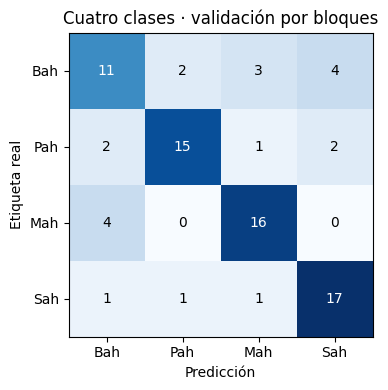

In [28]:
import numpy as np
import matplotlib.pyplot as plt

matriz_cv_4 = np.array([
    [
        np.count_nonzero(
            (y_4 == real) & (predicciones_cv_4 == predicha)
        )
        for predicha in clases_modelo_4
    ]
    for real in clases_modelo_4
])

fig_conf_4, ax_conf_4 = plt.subplots(figsize=(5, 4))

ax_conf_4.imshow(matriz_cv_4, cmap="Blues", vmin=0)

ax_conf_4.set_xticks(
    range(len(clases_modelo_4)),
    labels=clases_modelo_4,
)
ax_conf_4.set_yticks(
    range(len(clases_modelo_4)),
    labels=clases_modelo_4,
)

ax_conf_4.set_xlabel("Predicción")
ax_conf_4.set_ylabel("Etiqueta real")
ax_conf_4.set_title("Cuatro clases · validación por bloques")

for fila_4 in range(len(clases_modelo_4)):
    for columna_4 in range(len(clases_modelo_4)):
        valor_4 = matriz_cv_4[fila_4, columna_4]

        ax_conf_4.text(
            columna_4, fila_4, str(valor_4),
            ha="center",
            va="center",
            color=(
                "white"
                if valor_4 > matriz_cv_4.max() / 2
                else "black"
            ),
        )

fig_conf_4.tight_layout()
plt.show()

con cuatro clases ha acertado 59 de 80 ensayos (73,8 %), bah es el que peor sale y se confunde con las otras tres clases, se equivoca más entre Bah y Mah y Sah es el que más acierta